# GG4257 - Creating Sustainable Cities with Spatial Data Science

## Lab Assignment 2: Networks, Geodemographics and Spatial Microsimulation

## Coursework Cover Page
* **Student ID:** 230020257
*  **Degree Programme:** Geography
*  **Deadline Date:** 12th of November, 2026

## Declaration
In submitting this assignment I hereby confirm that:

I have read the University's statement on Good Academic Practice; that the following work is my own work; and that significant academic debts and borrowings have been properly acknowledged and referenced.


## GitHub Repository
* **GitHub Link:** https://github.com/BrodieHutcheson/GG4257-Assignment-2

## Introduction
This notebook explores the application of spatial data science techniques to understand real world geographical problems. The following notebook is structured as three labs that have challenges within them, each addressing different geospatial topics. Lab 1 focused on APIs to retrieve and manipulate data as well as choropleth mapping. The 2nd lab looked at network analysis and accessibility within cities. Specifically, access to amenities and green space. Finally, lab 3 looked at geodemographic classifications using census data alongside k-means clustering.
### Reproducibility
All of the code and outputs for the challenges are displayed within this notebook. The GitHub repository link can be found above so all of the following code can be reproduced. The data used for these challenges are also stored within the accompanying GitHub repository, along with screenshots of the code outputs

**Note:** some of the data is retrieved directly from an API, therefore this data is not stored within the repository

# Lab 1

## Challenge 1: Urban Heat Islands
This challenge follows an ArcGIS tutorial that studies the urban heat island effect in Richmond, Virginia. In this tutorial, 3 layers that contribute to this effect are mapped into an interactive dashboard and split into census block groups. The layers are temperature, tree canopy coverage and impervious surface coverage.

The heat island effect is where urban areas such as cities experience greater temperatures than nearby rural areas as the built up area essentially absorbs and retains heat. This is due to a lack of vegetation and the abundance of man-made materials that absorb heat. 

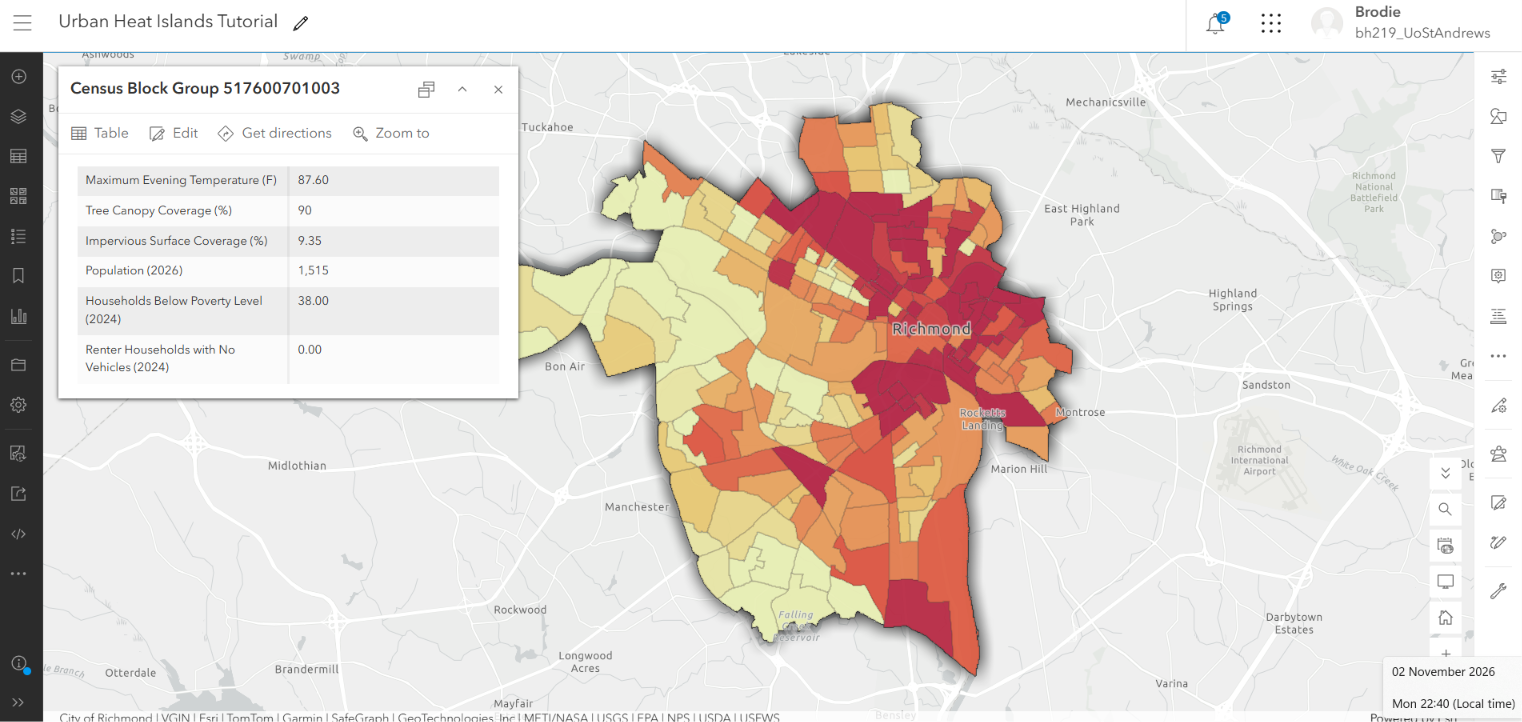

Dashboard link: https://www.arcgis.com/apps/mapviewer/index.html?webmap=fb9c51ed506e4b8f9a45dacfc210e2f1

## Challenge 2: Part 1 - Choropleth Mapping using Different Classification Methods
In this challenge I used the Scottish Index of Multiple Deprivation (SIMD) 2020 dataset to map crime rate within Edinburgh. I used both the natural breaks and equal intervals classification method for crime rate in Edinburgh and compared the choropleth map outputs side by side. This was done to visualise how how 2 maps can appear different, despite the attributes being the same. 

In [ ]:
from shapely.geometry import Polygon  
import requests
import pandas as pd                           # importing necessary python libraries for importing data, analysis and mapping
import geopandas as gpd
import mapclassify as mc
import matplotlib.pyplot as plt
import folium
import seaborn as sns

url_edinburgh = "https://maps.gov.scot/server/rest/services/ScotGov/PeopleSociety/MapServer/7/query?where=laname%3D%27City+of+Edinburgh%27&text=&objectIds=&time=&timeRelation=esriTimeRelationOverlaps&outFields=*&returnGeometry=true&f=geojson"
                                                                                       # defines the API URL under the variable name "url_edinburgh"
response_edinburgh = requests.get(url_edinburgh)  # use requests.get to request an API response
response_edinburgh  # store the API response

In [ ]:
data = response_edinburgh.json()  # converts API response into a format that python can read

In [ ]:
gdf = gpd.GeoDataFrame.from_features(data["features"])  # convert the geographical features from the API response into a geodataframe
gdf.head()  # display the 1st 5 rows of the geodataframe

In [ ]:
gdf.crs is None  # check if the geodataframe has an assigned crs

In [ ]:
gdf = gdf.set_crs('epsg:4326')  # set the geodataframe to the crs 'epsg:4326'

In [ ]:
gdf.columns  # display the columns of the geodataframe

In [ ]:
num_classes = 5  # set number of classification categories to 5

classifier_nb = mc.NaturalBreaks(gdf['crimerate'], k=num_classes)      # classify crime rates into 5 categories using the natural breaks method
print(classifier_nb)  # display the classification summary
print(min(classifier_nb.bins), max(classifier_nb.bins))  # display the min and max classification boundaries
print(classifier_nb.bins)  # display all classification boundaries


classifier_ei = mc.EqualInterval(gdf['crimerate'], k=num_classes)      # classify crime rates into 5 categories using the equal intervals method
print(classifier_ei)
print(min(classifier_ei.bins), max(classifier_ei.bins))
print(classifier_ei.bins)

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8))  # create a figure with 2 plots side by side

gdf.plot(column='crimerate', ax=axs[0],          # create chorpleth map using natural breaks method
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_nb.bins}
        )

axs[0].set_title("Choropleth Map of Edinburgh crime rate with Natural Breaks")  # title the map

gdf.plot(column='crimerate', ax=axs[1],  # create chorpleth map using equal interval method
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_ei.bins})

axs[1].set_title("Choropleth Map of Edinburgh crime rate with Equal Intervals")  # title the map

plt.tight_layout() 
plt.show()  # display the side by side maps

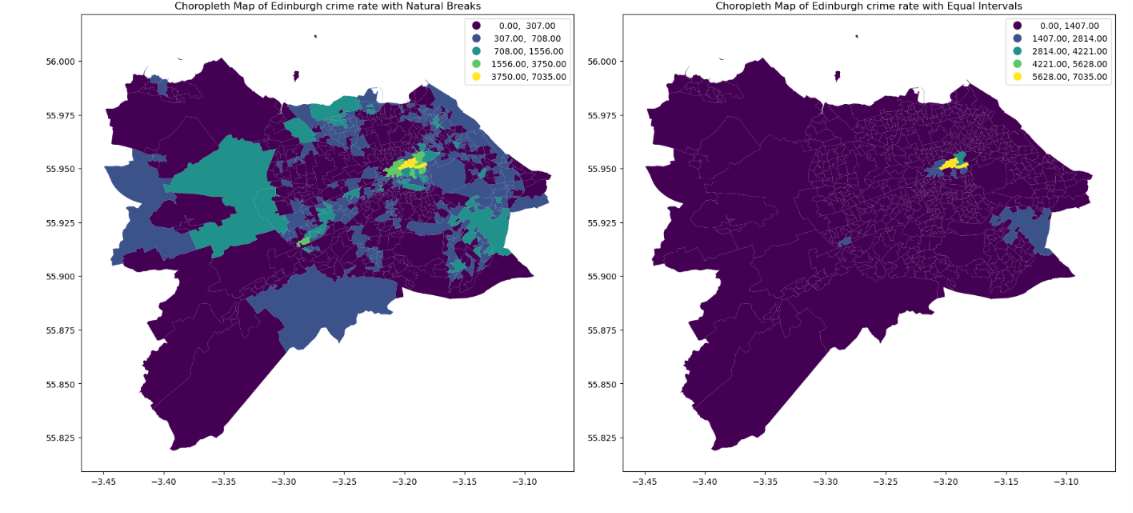

## Discussion
From the maps above, it's clear that the classification method has had an impact on the outputs, despite the attributes being the same. For example, the choropleth using the natural breaks method displays a relatively high variation in the spatial distribution of crime rate whereas the choropleth using equal intervals classification displays very low variation. This is because the equal intervals classification divides data ranges into equal intervals, meaning that if Edinburgh has a relatively low crime rate, then many areas are likely to be categorised into the 1st two data ranges. On the other hand, natural breaks classification finds natural groupings based on data distribution, therefore differences between areas may become more visible.

## Part 2: Deprivation Comparison Between Glasgow and Edinburgh
For this challenge I created 2 interactive choropleths to compare the deprivation ranking between Glasgow and Edinburgh. This analysis also uses the Scottish Index of Multiple Deprivation (SIMD) 2020 dataset with the data being retrieved via and API. The choropleth output is intended to show the difference in deprivation between both cities as well as the variation in the spatial distribution of deprivation ranking within the cities aswell

In [ ]:
gdf.explore(                 # create an interactive map using .explore
    column="rankv2",  # use rankv2 (deprivation ranking) as the attribute to map
    cmap="viridis",  # select colour scale
    tooltip=["dzname", "rankv2"],  # display area name and deprivation ranking when hovering over the area
    tiles="Esri.WorldGrayCanvas", # use grey basemap as the background
    style_kwds={"color": "white", "weight": 0.5, "fillOpacity": 0.8},  
)

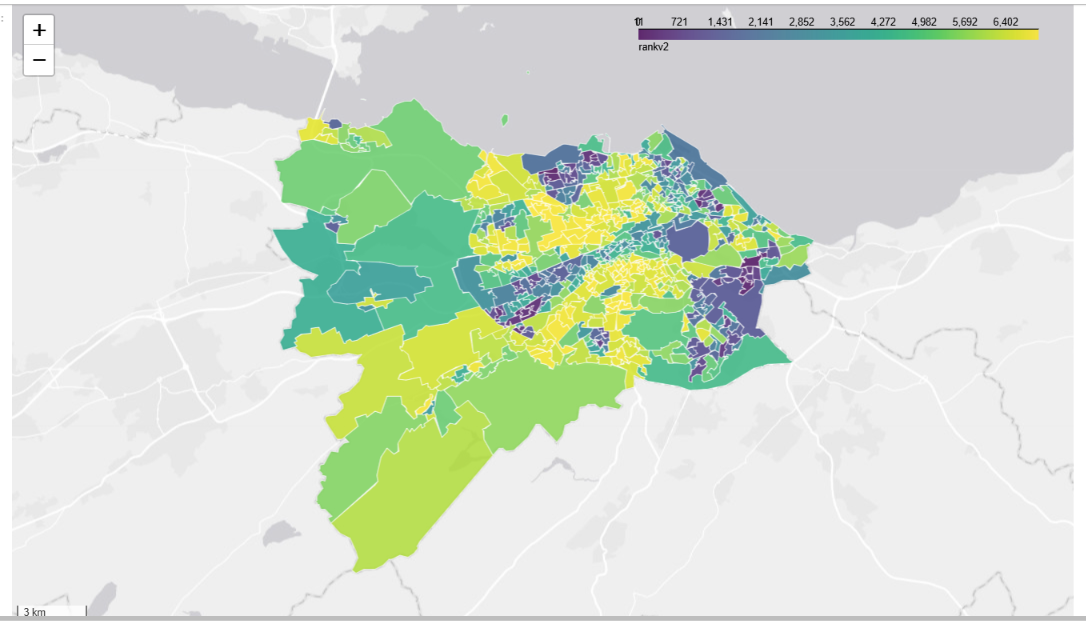

In [ ]:
url_glasgow ="https://maps.gov.scot/server/rest/services/ScotGov/PeopleSociety/MapServer/7/query?where=LAName%3D%27Glasgow+City%27&text=&objectIds=&time=&timeRelation=esriTimeRelationOverlaps&geometry=&geometryType=esriGeometryEnvelope&inSR=&spatialRel=esriSpatialRelIntersects&distance=&units=esriSRUnit_Meter&relationParam=&outFields=*&returnGeometry=true&returnTrueCurves=false&maxAllowableOffset=&geometryPrecision=&outSR=&havingClause=&returnIdsOnly=false&returnCountOnly=false&orderByFields=&groupByFieldsForStatistics=&outStatistics=&returnZ=false&returnM=false&gdbVersion=&historicMoment=&returnDistinctValues=false&resultOffset=&resultRecordCount=&returnExtentOnly=false&sqlFormat=none&datumTransformation=&parameterValues=&rangeValues=&quantizationParameters=&featureEncoding=esriDefault&f=geojson"
                                                                 # defines the API URL under the variable name "url_glasgow"
response_glasgow = requests.get(url_glasgow)  # use requests.get to request an API response
response_glasgow  # store the API response

In [ ]:
data = response_glasgow.json()  # converts API response into a format that python can read

In [ ]:
gdf = gpd.GeoDataFrame.from_features(data["features"])  # convert the geographical features from the API response into a geodataframe
gdf.head()  # display the 1st 5 rows of the geodataframe

In [ ]:
gdf.crs is None  # check if the geodataframe has an assigned crs

In [ ]:
gdf = gdf.set_crs('epsg:4326')  # set the geodataframe to the crs 'epsg:4326'

In [ ]:
gdf.columns  # display the columns of the geodataframe

In [ ]:
gdf.explore(  # create an interactive map using .explore
    column="rankv2",  # use rankv2 (deprivation ranking) as the attribute to map
    cmap="viridis",  # select colour scale
    tooltip=["dzname", "rankv2"],  # display area name and deprivation ranking when hovering over the area
    tiles="Esri.WorldGrayCanvas",  # use grey basemap as the background
    style_kwds={"color": "white", "weight": 0.5, "fillOpacity": 0.8},
)

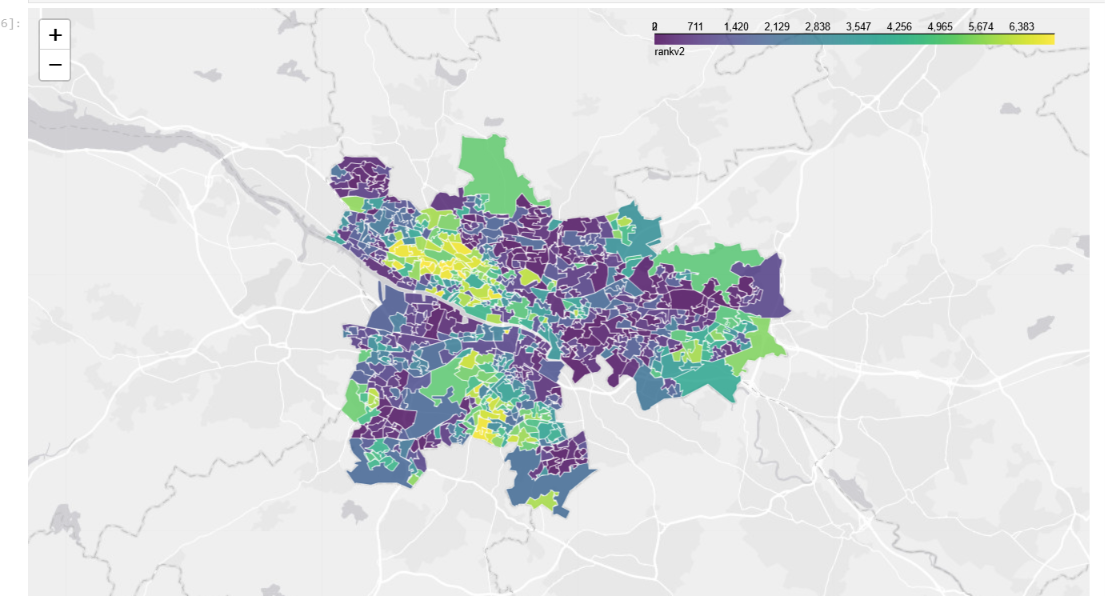

## Discussion
When comparing the deprivation choropleth for Glasgow and Edinburgh, there are clear differences between both cities for this metric. For Edinburgh, high levels of deprivation is mostly contained to the very centre, whereas for Glasgow, high levels of deprivation can be found across many areas spanning outwards from the centre. The initial visualisation from both choropleths are significantly different with Edinburgh having lots of green and yellow areas categorised as low deprivation whereas Glasgow has many areas of dark blue being categorised as high deprivation. This displays a large disparity between Scotland's 2 biggest cities and highlights the work that must be done to tackle this issue

# Lab 2

## Challenge 1: Amsterdam 15 Minute Neighbourhood
For this challenge I examined the accessibility of parks and everyday services for the De Pijp neighbourhood of Amsterdam to understand if it can be classed as a 15 minute neighbourhood. I used an overture places dataset to get amenities such as schools, food shops, healthcare, parks and public transportation. Isochrones were then generated to display which of these amenities were accessible within a 5, 10 and 15 minute walk of peoples homes. Futhermore, a two-step floating catchment area (2SFCA) method was used to calculate the ratio of park space per building to map accessibility to parks within a 15 minute walk. 

In [ ]:
import pandas as pd
import geopandas as gpd
import networkx as nx                              # importing necessary python libraries
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

In [ ]:
G_walk = ox.load_graphml("data/amsterdam_walk.graphml")  # load in the Amsterdam walking network data
G_walk = ox.project_graph(G_walk)  # project the walking network to a suitable crs

nodes, walk_edges = ox.graph_to_gdfs(G_walk)  # convert to a geodataframe with its nodes and edges
crs = G_walk.graph["crs"]  # store the crs of the walking networks data

parks = gpd.read_file("data/amsterdam_parks.gpkg").to_crs(crs)  # load in the Amsterdam parks dataset and project it as the same crs as walking networks
    
buildings = gpd.read_file("data/amsterdam_buildings.gpkg").to_crs(crs)  # load in the buildings dataset and project it as the same crs as walking networks
    
places = gpd.read_file("data/amsterdam_overture_places.gpkg").to_crs(crs)  # load in the overture places dataset and project it as the same crs as walking networks

In [ ]:
print("Walk network:", len(G_walk), "junctions")  # print the total number of junctions in the walking network

In [ ]:
places["basic_category"].unique()  # display service categories in the overture places dataset 

In [ ]:
AMSTERDAM = (52.3540, 4.8930)  # define centre coordinates of the study area
AREA = 2000  # define 2km study area radius
network_type = "walk"  # define network type as walking 
WALK_SPEED = 80  # set walking speed to 80 meters per minute 
WALK_LIMIT = 1200  # set the max walking distance for the 15 minute neighborhood

In [ ]:
SERVICES = {                                           # define the basic category types from the overture places dataset
    "School": ["elementary_school",  "high_school", "preschool", "specialty_school"],
    "Food shop": ["food_and_beverage_store", "convenience_store", "superstore", "market"],
    "Healthcare": ["hospital", "pharmacy_and_drug_store", "primary_care_or_general_clinic", "medical_service", "health_care", "dental_care"],
    "Park": ["park", "playground", "dog_park"],
    "Public transportation": ["train_station", "public_transit_facility_or_service"]}

In [ ]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)  # convert walking networks into a geodataframe with its nodes and edges

residential_area = unary_union(list(buildings.geometry))  # put all buildings into a 1 one geometry and define as "residential area"

centre = gpd.GeoSeries.from_xy([AMSTERDAM[1]], [AMSTERDAM[0]], crs="EPSG:4326").to_crs(crs)  # create a geoseries for the centre of the study area and set to the same crs as walking networks
    
neighbourhood = centre.buffer(AREA).iloc[0]  # create a 2km buffer from the centre of the study area and define as "neighbourhood"

homes = walk_nodes[ walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()  # identify nodes that are both within the buildings geometry and the neighbourhood buffer area
   
print(len(homes), "residential junctions in the neighbourhood")  # print the total number of residential nodes (junctions) within the neighbourhood

In [ ]:
def isochrone(G_walk, start_node, metres):  # define a function that creates an isochrone around a start point in the walking network
    reachable = nx.ego_graph(G_walk, start_node, radius=metres, distance="length")  # identify the reachable nodes within the sepecificed distance
    streets = ox.graph_to_gdfs(reachable, nodes=False)  # convert the reachable network into a geodataframe
    return unary_union(list(streets.buffer(50)))  # put a 50m buffer on the street geometry and combine into 1 geometry

In [ ]:
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])  # identify the walking network node nearest the centre of the study area

fig, ax = plt.subplots(figsize=(9, 9))  # create an accessibility map
walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)  # display the walking network as light grey
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:  # create 5, 10 and 15 minute isochrones, each a different colour
    shape = isochrone(G_walk, home, minutes * WALK_SPEED)  # calculate the reachable area within the walking time
    gpd.GeoSeries([shape], crs=crs).plot(ax=ax, color=colour, alpha=0.8)  # convert the isochrones into a geoseries and plot it 

iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)  # create the 15 minute isochrone
inside = places[places.within(iso15)]  # select the service categories within the 15 minute isochrone
for (name, categories), colour in zip(SERVICES.items(), ["#608738", "#C22A22", "#785596", "#2a9d8f", "#F4C900"]):  # give each service category a different colour
    selected = inside[inside["basic_category"].isin(categories)].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)
   

ax.legend(loc="lower left")  # add a legend
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from Amsterdam De Pijp, with services inside")  # add a title
ax.set_axis_off()
plt.show()  # plot the map

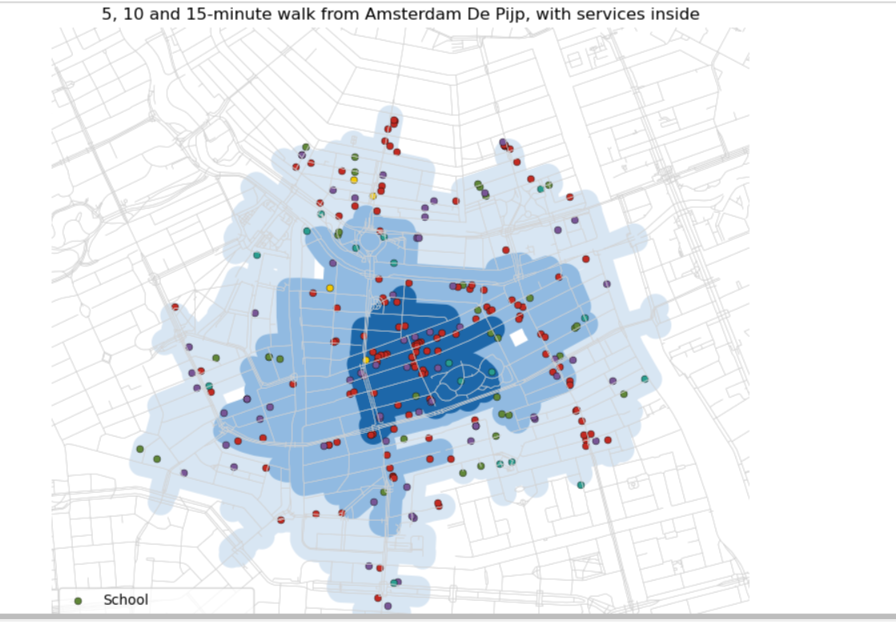

In [ ]:
iso5 = isochrone(G_walk, home, 5 * WALK_SPEED)
iso10 = isochrone(G_walk, home, 10 * WALK_SPEED)                      # create isochrones for 5, 10 and 15 minutes from the centre
iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)

inside5 = places[places.within(iso5)]
inside10 = places[places.within(iso10)]                    # identify the overture services within each isochrone
inside15 = places[places.within(iso15)]

for name, categories in SERVICES.items():     # use for loop to go through each service type in the service dictionary created
    print("\n", name)
    print("5 minutes:", len(inside5[inside5["basic_category"].isin(categories)]))
    print("10 minutes:", len(inside10[inside10["basic_category"].isin(categories)]))               # print total number of the chosen services within each isochrone
    print("15 minutes:", len(inside15[inside15["basic_category"].isin(categories)]))

In [ ]:
CITY = "AMSTERDAM"  # define the name of the study area
parks["area_m2"] = parks.area  # calculate the area of each park in meters squared

print(len(parks), "parks and", len(buildings), "buildings in", CITY)  # print the total number of parks and buildings in the study area

In [ ]:
parks["node"] = ox.distance.nearest_nodes(G_walk, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_walk, buildings.representative_point().x, buildings.representative_point().y)
                                                # assign each park and building to its nearest walking network node
demand = buildings["node"].value_counts()  # count the number of buildings associated to each walking network node       
demand.head()  # display the walking network nodes with the highest number of buildings associated

In [ ]:
reach = {}               # create empty dictionaries to store buildings near parks and the ratio of park to building
ratio = {}          

for park_id, park in parks.iterrows():  # loop through each park_id to see how many buildings are within a 15 minute walk
    nearby = nx.single_source_dijkstra_path_length(G_walk, park["node"], cutoff=WALK_LIMIT, weight="length")  # find the walking network nodes from the park within the walk limit
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)  # count buildings within nearby network nodes
    reach[park_id] = nearby  # store the nearby walking network nodes for each park
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0  # calculate and store the ratio of park space to buildings

parks["m2_per_building"] = pd.Series(ratio)  # add the ratio to the parks dataset
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)  # display the 10 parks with the highest park space to buidlings ratio

In [ ]:
city_nodes, city_edges = ox.graph_to_gdfs(G_walk)  # convert the walking networks to a geodataframe with the nodes and edges
park_access = {node: 0.0 for node in G_walk.nodes}  # create a dictionary to store the park space available at each walking network node

for park_id, nearby in reach.items():  # loop through every park and walking network nodes reachable from it 
    for node in nearby:
        park_access[node] += ratio[park_id]          # add the parks to buildings ratio to every nearby walking network node

city_nodes["park_access"] = pd.Series(park_access)  # add the ratio values to the walking network nodes dataset

homes_city = city_nodes[city_nodes.index.isin(demand.index)]  # select the walking network nodes associated with the buildings geometry
homes_city["park_access"].describe().round(0)  # show summary statistics

In [ ]:
homes_800m = homes_city[homes_city.within(centre.buffer(800).iloc[0])].copy()  # select homes within 800m of the study area

fig, ax = plt.subplots(figsize=(9, 9))  # create a figure to map park accessibility
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)  # display the walking network as light grey
parks.plot(ax=ax, color="#a8d5a2")  # plot the parks as green
homes_800m.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,  # categorise 5 accessibility values using the quantiles method
                                           markersize=8, legend=True,  # add a legend
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})  # add a legend title
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")  # add a map title
ax.set_axis_off()
plt.show()  # plot the parks accessibility map

print(f"{(homes_800m['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")  # calculate and print the number of homes with no park accessibility

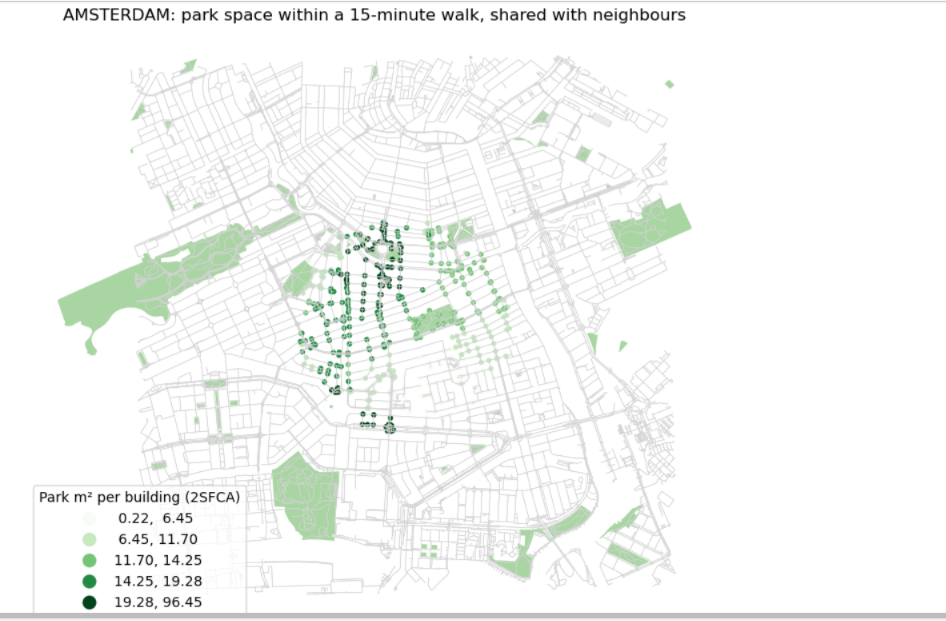

In [ ]:
service_counts = {}  # create an empty dictionary to store the number of services

for name, categories in SERVICES.items():  # loop through every service name and its associated categories
    service_counts[name] = len(inside15[inside15["basic_category"].isin(categories)])  # filter for the basic categories already established
        
print(service_counts)  # print the service counts

In [ ]:
summary = pd.DataFrame({               # create a dataframe for summary statistics
    "Measure": [
        "Number of parks",
        "Number of buildings",
        "Number of homes",
        "Median park space per building (m²)",
        "Homes with no park within 15 minutes (%)",
        "Schools within 15 minutes",
        "Food shops within 15 minutes",
        "Healthcare facilities within 15 minutes",
        "Parks within 15 minutes",
        "Public transport within 15 minutes"
    ],

    "Result": [
        len(parks),                                 
        len(buildings),
        len(homes_city),
        round(homes_city["park_access"].median(), 2),  
        round((homes_city["park_access"] == 0).mean() * 100, 1),
        service_counts["School"],
        service_counts["Food shop"],
        service_counts["Healthcare"],
        service_counts["Park"],
        service_counts["Public transportation"]
    ]
})

summary

## Conclusion: Accessibility Analysis of De Pijp, Amsterdam

After thorough analysis, it can be concluded that the De Pijp neighbourhood of Amsterdam is a 15 minute neighbourhood. When analysing access to amenities such as schools, food schops, healthcare, parks and public transportation the data shows that these amenities are widely available within a 15 minute walk from the centre of the De Pijp neighborhood. For example, there are 33 schools, 134 food shops and 17 parks within a 15 minute walk from the centre of the study area. Furthermore, when focusing on access to green space, the map above shows parks shared between homes and concludes that 0% of homes have no park within a 15 minute walk. An important caveat and limitation of this analysis is that assumptions are being made about which buildings are homes. There is no specific residential classification so non-residential buildings may be incorporated in the park access analysis.

# Lab 3

## Challenge 1: Geodemographic Classification and K-means Clustering
For this challenge I applied geodemographic classifications to identify neighbourhoods with similar demographic and socioeconomic characteristics within the city of Dundee. This was done using 2022 Scottish census data that was then filtered to the study area of Dundee. The variables used for this analysis were the the percentage of people between 16 and 24 years old, the percentage of people classed as in very good health, the percentage of households who are renting social accommodation and the percentage of people with no qualifications. The rationale behind these chosen variables was that it covered a wide range of characteristics that could be used understand spatial patterns across the city. This analysis also applied standardisation and k-means clustering to group areas based on these chosen characteristics. 

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd                                             # importing necessary python libraries
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import os
pd.set_option("display.precision", 2)
RANDOM_SEED = 42

In [ ]:
csv_directory = "data/census_data"  # define the directory with the census csv files

csv_files = [file for file in os.listdir(csv_directory) if file.endswith(".csv")]  # get all the csv files within the directory

merged_data = pd.DataFrame()  # create a dataframe to store the merged data

for csv_file in csv_files:  # loop through all the csv files in the directory
    csv_path = os.path.join(csv_directory, csv_file)  # define the file path for the csvf file
    df_csv = pd.read_csv(csv_path, low_memory=False) # read in the csv file into a pandas dataframe
  
    merged_data = pd.concat([merged_data, df_csv], axis=1)  # merge the csv files

merged_data.to_csv("data/census_data/merged_census_data.csv", index=False)  

In [ ]:
shp_path = "data/scottish_boundary/OutputArea2022/OutputArea2022_MHW.shp"  # define the file path for the boundary shapefile
gdf = gpd.read_file(shp_path)  # read in the shapefile as a geodataframe

csv_path = "data/census_data/merged_census_data.csv"  # define file path of the csv
csv_data = pd.read_csv(csv_path, low_memory=False)  # read in the csv file as a pandas dataframe

# Merge the GeoDataFrame with the DataFrame based on the oa_code
merged_data = gdf.merge(csv_data, left_on='code', right_on='Unnamed: 0', how='left')  # merge the geodataframe with the pandas dataframe based on the area code



In [ ]:
list(merged_data.columns)  # display a list of columns for the merged census dataframe

In [ ]:
merged_data.info  # display info for the dataframe

In [ ]:
merged_data.shape  # display the dimensions of the dataframe

In [ ]:
merged_data.head()  # display the 1st 5 rows of the dataframe

In [ ]:
print(gdf['council'].value_counts())  # display the output areas 

In [ ]:
dundee_gdf = gdf[gdf['council'] == 'S12000042'].copy()  # select the output area of Dundee

# Check the result
print(dundee_gdf.shape)  # display dimensions of new geodataframe
print(dundee_gdf['council'].value_counts())  #display the output area 

In [ ]:
dundee_codes = dundee_gdf['code']  # get the code for Dundee output area

dundee_census = csv_data[csv_data['Unnamed: 0'].isin(dundee_codes)].copy()  # filter the data for Dundee

print(dundee_census.shape)  # display dimensions of the dataframe

In [ ]:
dundee_merged = dundee_gdf.merge(  # merge the Dundee output area and the census data based on the area code
    dundee_census,
    left_on='code',
    right_on='Unnamed: 0',
    how='left')


print(dundee_merged.shape)  # display the dimensions of the dataframe

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt      # import libraries for stats and plotting

attributes_to_plot = [   # select the census variables for plotting
    '16 - 24',
    'Very good',
    'Social Rented: Council (LA) or Housing Association/ Registered Social Landlord',
    'No qualifications'
]

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):  # go through all the variables to plot seperately
    plt.subplot(2, 2, i)
    sns.violinplot(x=dundee_merged[attribute])
    plt.title(attribute)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()  # plot the violin plot

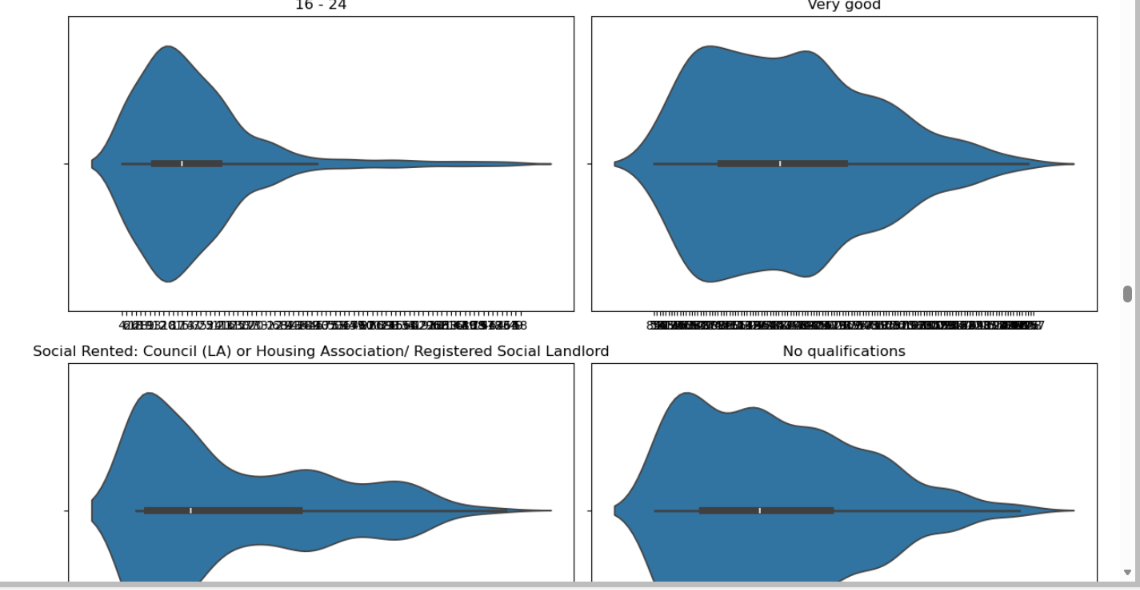

In [ ]:
def calculate_percentages(dataframe, total_columns, value_columns):  # define a function to calculate percentages for the variables

    result_df = pd.DataFrame()  # create a dataframe to store the percentages

    for total_col, value_col in zip(total_columns, value_columns):  # loop through the total column and the values column
        percentage_col_name = f"{value_col}_percentage"  # name the new percentage column

        if total_col not in dataframe.columns:  # check the total column exists in the dataframe
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")  # raise an error if it doesn't
    
        dataframe[value_col] = pd.to_numeric(dataframe[value_col], errors='coerce')  # convert to numerical values
        dataframe[total_col] = pd.to_numeric(dataframe[total_col], errors='coerce')  # convert to numerical values
        
        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100  # calculate percentage for each output area

    return result_df  # return the dataframe with the percentages


total_cols = [     # define the total column
    'Total',
    'All people',
    'All occupied households',
    'All people aged 16 and over' ]

value_cols = [  # define the values column
    '16 - 24',
    'Very good',
    'Social Rented: Council (LA) or Housing Association/ Registered Social Landlord',
    'No qualifications' ]

result_dataframe = calculate_percentages(dundee_merged, total_cols, value_cols)  # apply the function for the Dundee census dataset


In [ ]:
result_dataframe.head()  # display the 1st 5 rows of the new dataframe

In [ ]:
result_dataframe.shape  # display the dimensions of the dataframe

In [ ]:
concatenated_df = pd.concat([dundee_merged, result_dataframe], axis=1, ignore_index=False)  # combine the merged dataset with the percentages
concatenated_df.head()  # display the 1st 5 rows of the new dataframe

In [ ]:
concatenated_df.shape  # display the dimensions of the dataframe

In [ ]:
list(concatenated_df.columns)  # display the columns of the dataframe

In [ ]:
keep_cols = [        # define the columns to keep for analysis
    'code',
    'Popcount',
    'HHcount',
    'geometry',
    '16 - 24_percentage',
    'Very good_percentage',
    'Social Rented: Council (LA) or Housing Association/ Registered Social Landlord_percentage',
    'No qualifications_percentage' ]

dundee_census_data = concatenated_df[keep_cols]  # create a new dataframe with the selected columns

In [ ]:
dundee_census_data.head()  # display the 1st 5 rows of the new dataframe

In [ ]:
short_column_names = {                       # create a dictionary to rename the census variables
    '16 - 24_percentage': 'Age_16_24',
    'Very good_percentage': 'Very_Good_Health',
    'Social Rented: Council (LA) or Housing Association/ Registered Social Landlord_percentage': 'Social_Rented',
    'No qualifications_percentage': 'No_Qualifications' }


dundee_census_data = dundee_census_data.rename(columns=short_column_names)  # add the renamed columns to the dundee census dataframe

In [ ]:
dundee_census_data.head()  # display the 1st 5 rows of the dataframe

In [ ]:
dundee_census_data.info()  # display the info for the dataframe

In [ ]:
numeric_columns = dundee_census_data.select_dtypes(include='float64')  # select the columns with numerical data
z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)  # standardise the variables using z-scores
z_score_df.head()  # display the z scores for the variables

In [ ]:
z_score_df.shape  # display the dimensions of the dataframe

In [ ]:
corr = z_score_df.corr()  # calculate the correlation matrix for the variables
corr.style.background_gradient(cmap='coolwarm')  # display the matrix as a heatmap

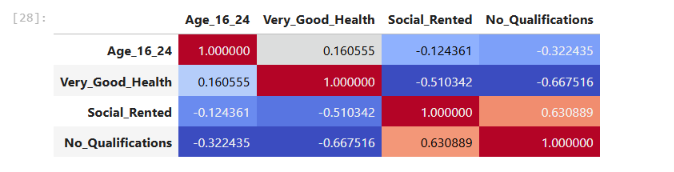

In [ ]:
threshold = 0.7   # set the correlation threshold to 0.7

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)  # identify pairs of variables with a correlation greater than 0.7 but exclude when variables are perfectly correlated with itslef

plt.figure(figsize=(10, 8))  # set the figure dimensions
sns.heatmap(highly_correlated, cmap='coolwarm', cbar=False, annot=True)  

plt.title('Highly Correlated Variables')  # add a title
plt.show()  # plot

## Chosen Variables
* The percentage of people between 16 and 24 years old
* The percentage of people classed as in very good health
* The percentage of households who are renting social accommodation
* The percentage of people with no qualifications.

Correlation tests did not result in any pairs of variables being above the threshold value of a 0.7 meaning no correlation was above this figure. This would be problematic as it would distort the clusters after analysis. As this was not the case, the use of these 4 variables were supported as suitable for geodemographic classification. 



In [ ]:
contains_nan = z_score_df.isna().any().any()  # check for missing values

if contains_nan:
    print("the DataFrame contains NaN values.")  # if missing values are found then this is printed
else:
    print("the dataFrame does not contain NaN values.")  # otherise, this is printed

In [ ]:
z_score_df.fillna(z_score_df.mean(), inplace=True)  # replace missing values with that columns mean

In [ ]:
z_score_df.head()  # display the 1st 5 rows of the cleaned dataframe

In [ ]:
z_score_df.shape  # display the dimensions of the new dataframe

In [ ]:
from sklearn.cluster import KMeans  # import k means clustering algorithm
from scipy.spatial.distance import cdist, pdist

kmeans = KMeans(n_clusters=10)  # set cluster groups to 10
kmeans.fit(z_score_df)  # fit k means model to the standardised variables
labels = kmeans.predict(z_score_df)  
cluster_centres = kmeans.cluster_centers_  # get coordinates of the cluster centres
z_score_df['Cluster'] = kmeans.labels_  # add cluster labels to the standardised dataframe

In [ ]:
z_score_df.head()  # display the 1st 5 rows of the standardised dataframe

In [ ]:
Sum_of_squared_distances = []  # create empty list to store the sum of squared distances

K_range = range(1,15)  # define the range of cluster group numbers

for k in K_range:  # loop through all numbers of clusters
 km = KMeans(n_clusters=k)  # apply k means algorithm for the current number of clusters
 km = km.fit(z_score_df)  # fit k means model to the standardised dataframe 
 Sum_of_squared_distances.append(km.inertia_)  # store the results in the list created
    
plt.plot(K_range, Sum_of_squared_distances, 'bx-')  # plot values against the number of clusters
plt.xlabel('k')  # label x axis
plt.ylabel('Sum_of_squared_distances')  # label y axis
plt.title('Elbow Method For Optimal k')  # add a title
plt.show()  # plot the elblow plot

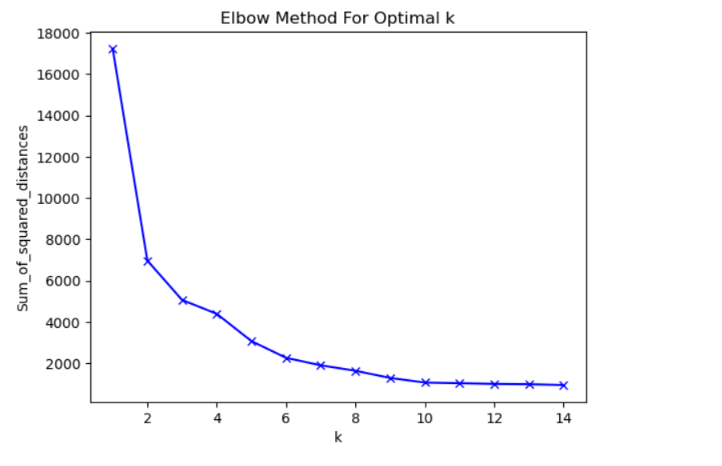

## Defining the Optimum number of cluster groups
From this elblow plot, we can see that the variation within cluster groups are greatly reduced when increasing from 2 to 6 clusters, however the variation plateaus after 6 cluster groups. This means that using any more than 6 cluster groups would provide progressively smaller improvements in reducing the variation of geodemographic characteristics within cluster groups. For this reason, 6 cluster groups was established as an appropriate number

In [ ]:
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.figure(figsize=(12, 8))  # set figure dimensions for the plot

kmeans = KMeans(n_clusters=6)  # set cluster number to 6
clusters = kmeans.fit_predict(z_score_df)  # fit the k means model to the standardised census data

z_score_df['Cluster'] = clusters  # add cluster labels to the standardised dataframe

scaler = StandardScaler()  
stand_data_scaled = scaler.fit_transform(z_score_df)  # standardise the dataset


pca = PCA(n_components=2).fit(stand_data_scaled)  # use pca to reduce the data to 2 components
pca_result = pca.transform(stand_data_scaled)  # convert the data into the 2 components

variance_ratio = pca.explained_variance_ratio_  # calculate variance for each component


fig = px.scatter(x=pca_result[:, 0], y=pca_result[:, 1], color=clusters,  # create a scatterplot
                 labels={'color': 'Cluster'},
                 #title='Cluster Plot against 1st 2 Principal Components',
                 opacity=0.7,
                 width=800, 
                 height=800)

plt.tight_layout()
fig.show()  # display the scatterplot

print(f"These two components explain {(variance_ratio.sum()*100):.2f}% of the point variability.")  # print the percentage variance for the 2 components together

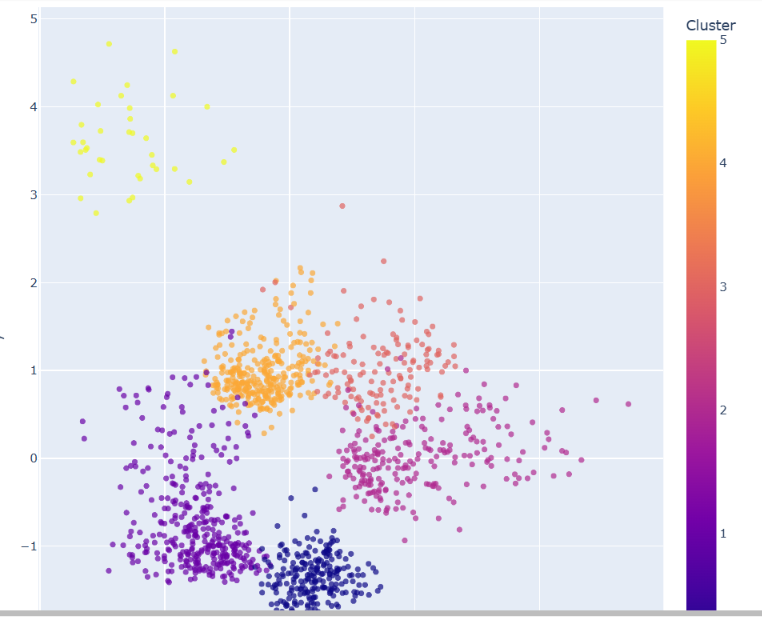

## Evaluation of Cluster Groups
The PCA plot above shows distinctive spatial distribution between cluster groups. This means that there is adequate variation in demographic and socioeconomic characteristics, therefore analysis and interpretation can show meaningful patterns across Dundee. There still remains some overlap in cluster groups meaning that some regions, particularly in the centre may have similar characteristics. Overall, the PCA plot supports the use of 6 cluster groups, however, the groups and not entirely distinct

In [ ]:
final_df = pd.concat([dundee_census_data, z_score_df], axis=1, ignore_index=False)  # combine the dundee census dataset with the standardised one
final_df.head()  # display the 1st 5 rows of the new combined dataframe

In [ ]:
duplicates = final_df.columns[final_df.columns.duplicated()].tolist()  # remove duplicates from the dataframe

print(duplicates) display the duplcates

In [ ]:
final_df = final_df.loc[:, ~final_df.columns.duplicated()]   # add cleaned dataframe

In [ ]:
kmeans = KMeans(n_clusters=6)  # initialise the k means clustering algorithm for 6 cluster groups
clusters = kmeans.fit_predict(z_score_df)  # fit the k means model to the standardised data

# Get the cluster centers
cluster_centers = kmeans.cluster_centers_  # get cluster centre coordinates



cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=z_score_df.columns)  # get the cluster centres


cluster_centers.head(6)  # display the characteristics of the cluster centres

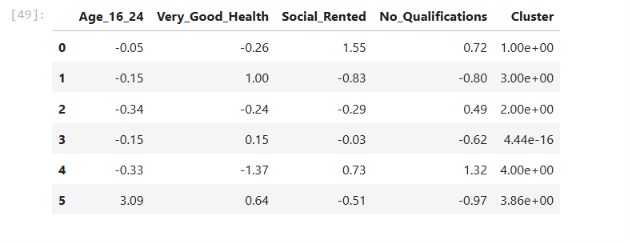

## Interpretation of Cluster Centres
**Cluster 0:** Cluster 0 displays a significantly higher proportion of social renting and a greater proportion of those with no qualifications. This could indicate regions of greater socioeconomic disadvantages.

**Cluster 1:** Cluster 1 has above average health and a significantly lower proportion of those with no qualifications. This could indicate better health and educational services.

**Cluster 2:** Cluster 2 has lower qualification levels and lower social renting. It represents quite varied demographic characteristics

**Cluster 3:** Cluster 3 displays very average variables relative to Dundee as a whole, however it has significantly higher qualification levels. Once again, it's quite mixed however it does represent a region with possibly good education. 

**Cluster 4:** Cluster 4 is very distinctive as it shows a lower proportion of those in good health as well as high social renting and low qualification levels. This demonstrates areas that may benefit from better healthcare and educational facilities.

**Cluster 5:** Cluster 5 is very demographically distinct as it has a very large percentage of 16-24 year olds compared with the rest of Dundee. Qualification levels are very high and health is above average. This could represent a young, student oriented neighbourhood

In [ ]:
final_df.explore(column='Cluster', cmap='Set1', tiles='CartoDB positron')  # map the k means clusters

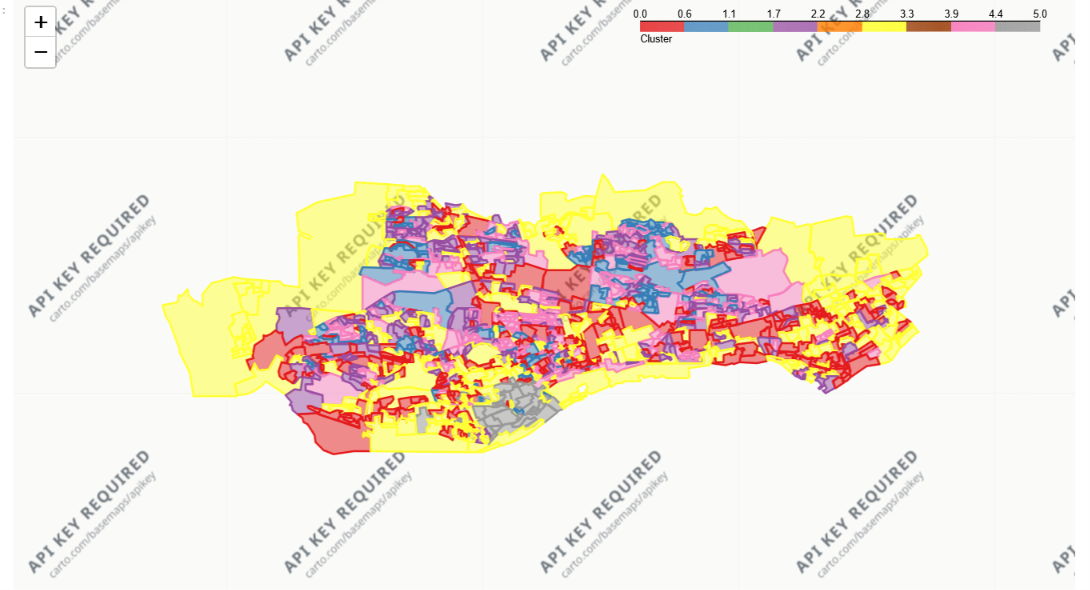

## Interpretations
From this interactive map, interpretations can be made based on the chosen geodemographic variables. These are the percentage of people between 16 and 24 years old, the percentage of people classed as in very good health, the percentage of households who are renting social accommodation and the percentage of people with no qualifications. The yellow regions have a low percentage of 16-24 year olds and a very low percentage of households in social renting. This demonstrates an older demographic of people who may own their own home. The blue regions show high social renting and lower qualification levels across the board. This may suggest that these neighbourhoods have higher socioeconomic disadvantages. These regions are found in the centre and towards the north of Dundee and do not appear to be distributed to the outskirts of the city. The red regions can be characterised with relatively poorer health and low social renting, with these regions being evenly distributed across the city. There is also a rather low percentage of 16-24 years old, however this older demographic is prevalent acrosss the majority of the city. The pink regions display poorer health and lower qualification levels with only about 30% of people being characterised as havng very good health. The combination of poorer health with lower qualification levels could demonstrate areas that may have a lack of eduactional and healthcare services. Finally, the grey regions are very distinct with having a very high percentage of 16-24 year olds, combined with high qualification levels and reletively high social renting. This region can be found to the south of the city and may represent a young, student orientated neighbourhood. 

In [ ]:
final_df['Cluster'] = final_df['Cluster'].astype(str)  # convert cluster labels to string format

def rename_column(x):  # define a function to rename the cluster labels
    x = x.replace("0", "Social Renting and Lower Qualifications")
    x = x.replace("1", "Healthier and Higher Qualification Areas")
    x = x.replace("2", "Demographically and Socioeconomically Mixed")
    x = x.replace("3", "Average Characteristics")
    x = x.replace("4", "Health and Qualification Disadvantage")
    x = x.replace("5", "Young Adult Concentration")

    return x  # return the descriptive cluster name

final_df['Cluster'] = final_df['Cluster'].apply(rename_column)  # apply the function for the cluster column

In [ ]:
final_df.explore(column='Cluster', cmap='Set1', tiles='CartoDB positron')  # map the k means clusters with the descriptive cluster labels

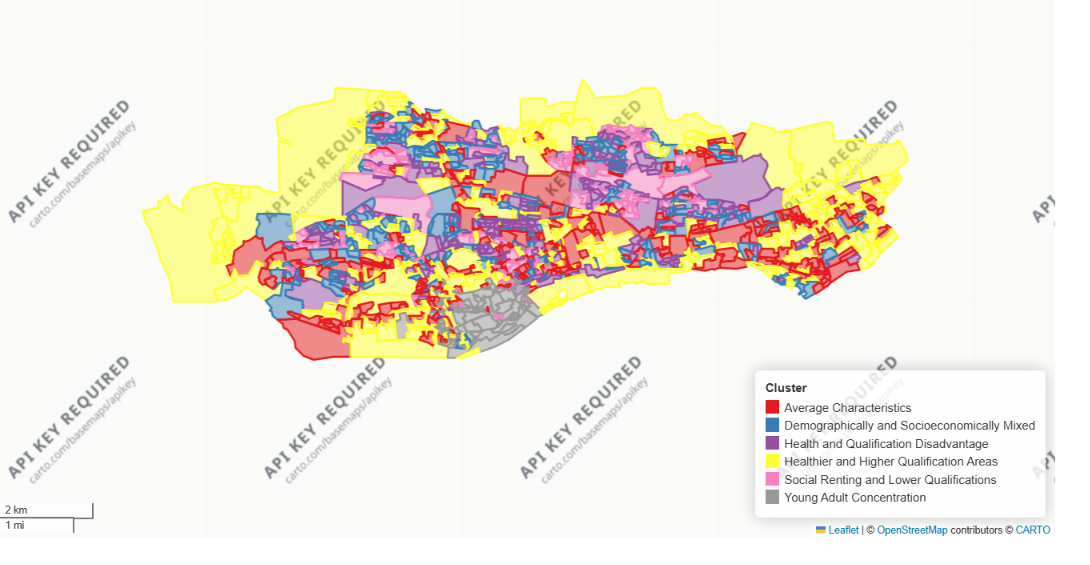

## Conclusion
Overall, this classification highlights how census data can be used to identify demographic an socioeconomic characteristics across Dundee. However, this classification can be subjective as the combined choice of variables and cluster group numbers has a large impact on the outcome of the classification. Subjectivity also exists when interpreting the results as assumptions are being made on a region based on only 4 variables. Challenges were also present in terms of data handling and pre processing as missing values had to be dealt with as well as csv file metadata. The result of this geodemographic classification has potential use cases regarding service planning within the city of Dundee. For example, areas of poorer health or low qualification levels could be identified as an area of interest for healthcare or educational facilities as a way to make all regions better for those who live within it. 